This notebook generates subject-specific NSD stimulus files resized to 256×256 pixels, saved as HDF5 files.
These files are used as input for texture feature extraction and downstream encoding models.

Each subject gets one output file containing all images they viewed.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


We move to the main code directory of the texturemodel project.

In [ ]:
%cd /content/drive/MyDrive/V2_drift/texturemodel/code
!ls



/content/drive/MyDrive/V2_drift/texturemodel/code
analyze_fits	    make_stimuli_256.py  run
compare		    model_fitting	 run_stimuli_creation.ipynb
feature_extraction  plotting		 utils


The script performs the following steps:

Loads the original NSD stimulus file
(nsd_stimuli.hdf5, shape ≈ 73k × 425 × 425 × 3)

For each subject:

Selects only the images shown to that subject

Resizes images to 256×256

Saves them as a single HDF5 file

Output format (per subject):

In [ ]:
!python make_stimuli_256.py


2026-01-12 14:44:24.256609: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1768229064.279653    7037 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768229064.286059    7037 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1768229064.302178    7037 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768229064.302204    7037 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768229064.302210    7037 computation_placer.cc:177] computation placer alr

checking befroe feature extract


In [2]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/V2_drift/texturemodel/code
!pwd
!ls


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/V2_drift/texturemodel/code
/content/drive/MyDrive/V2_drift/texturemodel/code
analyze_fits	    make_stimuli_256.py  run
compare		    model_fitting	 run_stimuli_creation.ipynb
feature_extraction  plotting		 utils


In [10]:
import os, h5py
from utils import default_paths

stim_root = default_paths.stim_root
fn = os.path.join(stim_root, "S8_stimuli_256.h5py")
print("stim_root:", stim_root)
print("exists:", os.path.exists(fn), fn)

with h5py.File(fn, "r") as f:
    print("keys:", list(f.keys()))
    x = f["stimuli"]
    print("stimuli shape:", x.shape, "dtype:", x.dtype)


stim_root: /content/drive/MyDrive/V2_drift/nsd/stimuli
exists: True /content/drive/MyDrive/V2_drift/nsd/stimuli/S8_stimuli_256.h5py
keys: ['stimuli']
stimuli shape: (10000, 3, 256, 256) dtype: uint8


Verify red fixation changes the center (numeric + visual)


Loading images for subject 1

image data size: (10000, 3, 256, 256) , dtype: uint8 , value range: 0 255
loaded: (4, 3, 256, 256) uint8 0 255
fixated: (4, 3, 256, 256) uint8
expected fixation size (pixels): 7
center patch mean RGB BEFORE: [137.33673 129.29082 125.61735]
center patch mean RGB AFTER:  [195.91327   64.39796   62.540817]
delta (after-before):        [ 58.576538 -64.89286  -63.07653 ]


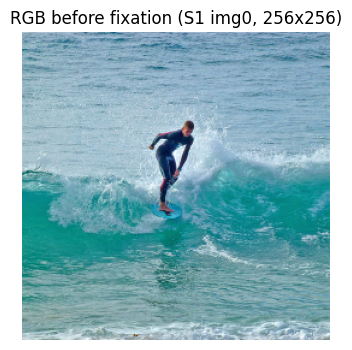

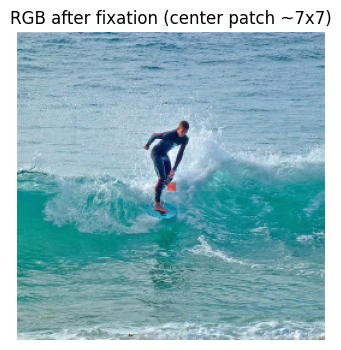

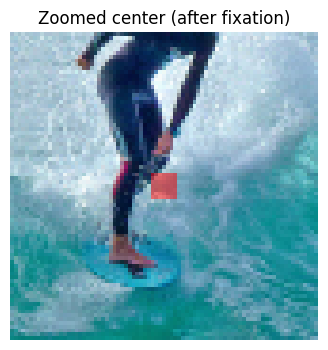

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from utils import nsd_utils

# Load a few images
imgs = nsd_utils.get_image_data(1, npix=256)[:4]   # (4,3,256,256) uint8
print("loaded:", imgs.shape, imgs.dtype, imgs.min(), imgs.max())

# Apply red fixation (RGB uint8) - NEW API (no size=...)
imgs_fix = nsd_utils.add_red_fixation_rgb_uint8(imgs)  # scaled fixation
print("fixated:", imgs_fix.shape, imgs_fix.dtype)

# --- Determine expected fixation size (same logic as function) ---
H, W = imgs.shape[2], imgs.shape[3]
base = min(H, W)
ref_size, ref_patch = 714, 17

target = int(round(base * (ref_patch / ref_size)))
if target % 2 == 0:
    target += 1
target = max(3, target)  # matches default min_patch=3
print("expected fixation size (pixels):", target)

# Numeric check: center patch should become "redder"
cx, cy = H // 2, W // 2
half = target // 2
x0, x1 = cx - half, cx + half + 1
y0, y1 = cy - half, cy + half + 1

before_patch = imgs[:, :, x0:x1, y0:y1].astype(np.float32)
after_patch  = imgs_fix[:, :, x0:x1, y0:y1].astype(np.float32)

before_mean_rgb = before_patch.mean(axis=(0,2,3))
after_mean_rgb  = after_patch.mean(axis=(0,2,3))

print("center patch mean RGB BEFORE:", before_mean_rgb)
print("center patch mean RGB AFTER: ", after_mean_rgb)
print("delta (after-before):       ", after_mean_rgb - before_mean_rgb)

# Visual check: show image 0 before/after
im0_before = imgs[2].transpose(1,2,0)
im0_after  = imgs_fix[2].transpose(1,2,0)

plt.figure(figsize=(4,4))
plt.imshow(im0_before)
plt.title("RGB before fixation (S1 img0, 256x256)")
plt.axis("off")
plt.show()

plt.figure(figsize=(4,4))
plt.imshow(im0_after)
plt.title(f"RGB after fixation (center patch ~{target}x{target})")
plt.axis("off")
plt.show()

# Zoom-in on the center region to see the patch clearly
zoom = 40
zx0, zx1 = cx - zoom, cx + zoom + 1
zy0, zy1 = cy - zoom, cy + zoom + 1

plt.figure(figsize=(4,4))
plt.imshow(im0_after[zx0:zx1, zy0:zy1])
plt.title("Zoomed center (after fixation)")
plt.axis("off")
plt.show()


Verify grayscale conversion (shape/range + visual)

Dask
BW shape: (4, 1, 256, 256)
grayscale: (4, 1, 256, 256) float32 0.0 1.0
grayscale center mean: 0.36166283
grayscale outer mean:  0.5107823
delta: -0.14911947


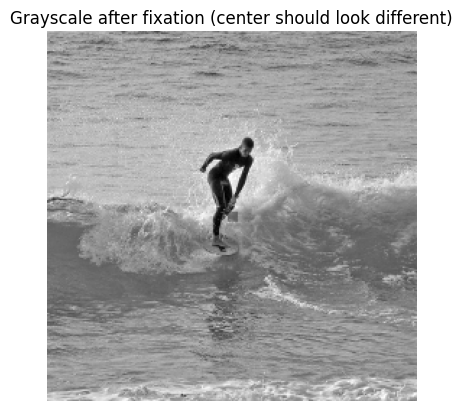

In [5]:
# Convert to grayscale float32 [0,1]
bw = nsd_utils.image_uncolorize_fn(imgs_fix)  # expected (4,1,256,256) float32
print("grayscale:", bw.shape, bw.dtype, bw.min(), bw.max())
# Numeric grayscale check: center vs nearby
center_patch = bw[:, 0, x0:x1, y0:y1]
outer_patch  = bw[:, 0, x0+target*2:x1+target*2, y0:y1]

print("grayscale center mean:", center_patch.mean())
print("grayscale outer mean: ", outer_patch.mean())
print("delta:", center_patch.mean() - outer_patch.mean())

# Visual grayscale
plt.figure()
plt.imshow(bw[2,0], cmap="gray")
plt.title("Grayscale after fixation (center should look different)")
plt.axis("off")
plt.show()


Smoke test: run feature extraction on a tiny subset

In [18]:
!pip install pyrtools


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.5/116.5 kB 11.1 MB/s eta 0:00:00


In [8]:
import torch
from model_fitting import initialize_fitting
from feature_extraction import texture_statistics_pyramid
from utils import torch_utils

# -------------------------------------------------
# Smoke test: 2 images, 2 pRFs
# -------------------------------------------------

# Use only 2 images
image_data = bw[:2]    # (2,256,256) float32
print("image_data:", image_data.shape, image_data.dtype,
      image_data.min(), image_data.max())

# Torch device
device = initialize_fitting.init_cuda() if torch.cuda.is_available() else "cpu:0"
print("device:", device)

# Build pRF models (take only first 2)
models = initialize_fitting.get_prf_models(which_grid=5)[:2]
print("models shape:", models.shape)

# Feature extractor params (MATCH FULL RUN)
n_ori = 4
n_sf = 4
batch_size = 2
n_prf_sd_out = 2
aperture = 1.0

_fmaps_fn = texture_statistics_pyramid.steerable_pyramid_extractor(
    pyr_height=n_sf,
    n_ori=n_ori
)

_feature_extractor = texture_statistics_pyramid.texture_feature_extractor(
    _fmaps_fn,
    sample_batch_size=batch_size,
    n_prf_sd_out=n_prf_sd_out,
    aperture=aperture,
    device=device
)

# Move image batch to torch
image_batch = torch_utils._to_torch(image_data, device)
_feature_extractor.clear_big_features()

# Run for each pRF
for mm in range(models.shape[0]):
    feats = _feature_extractor(image_batch, models[mm], mm)
    feats_np = torch_utils.get_value(feats)

    print(
        f"model {mm}:",
        feats_np.shape,
        feats_np.dtype,
        "min/max:",
        feats_np.min(),
        feats_np.max()
    )

print(" Feature extraction smoke test PASSED.")


image_data: (2, 1, 256, 256) float32 0.0 1.0
#device: 1
device#: 0
device name: Tesla T4

torch: 2.9.0+cu126
cuda:  12.6
cudnn: 91002
dtype: torch.float32
device: cuda:0
models shape: (2, 3)
Clearing steerable pyramid features from memory.
Running steerable pyramid feature extraction...
Images array shape is:
torch.Size([2, 1, 256, 256])
time elapsed = 0.31384
Computing higher order correlations...
time elapsed = 1.93735
Final size of features concatenated is [2 x 641]
Feature types included are:
['pixel_stats', 'mean_magnitudes', 'mean_realparts', 'marginal_stats_lowpass_recons', 'variance_highpass_resid', 'magnitude_feature_autocorrs', 'lowpass_recon_autocorrs', 'highpass_resid_autocorrs', 'magnitude_within_scale_crosscorrs', 'real_within_scale_crosscorrs', 'magnitude_across_scale_crosscorrs', 'real_imag_across_scale_crosscorrs', 'real_spatshift_within_scale_crosscorrs', 'real_spatshift_across_scale_crosscorrs']

WARNING THERE ARE ZEROS IN FEATURES MATRIX

zeros for columns:
(array([